# Fra kraftflyt til kraftvinkelligningen (SMIB)

## 1. Utgangspunkt: Kraftflytligningen

Vi starter med den komplekse effekten ved buss $k$:

$$
\bar S_k^{*}
=
P_k-jQ_k
=
\sum_{i=1}^{n}
\bar Y_{ki}\,\bar V_i\,\bar V_k^{*}
$$

Skriver vi alle størrelser på polar form:

$$
\bar Y_{ki}
=
|Y_{ki}|e^{j\theta_{ki}}
$$

$$
\bar V_i
=
|V_i|e^{j\delta_i}
$$

$$
\bar V_k^{*}
=
|V_k|e^{-j\delta_k}
$$

får vi

$$
P_k-jQ_k
=
\sum_{i=1}^{n}
|Y_{ki}||V_i||V_k|
e^{j(\theta_{ki}+\delta_i-\delta_k)}
$$

Den reelle delen gir aktiv effekt:

$$
P_k
=
\sum_{i=1}^{n}
|V_i||V_k||Y_{ki}|
\cos(\theta_{ki}+\delta_i-\delta_k)
$$

Dette er den vanlige kraftflytligningen.

![Kraftsystemligning](../images/power_flow_eq.png)



# 2. Stabilitetsmodell

I transient stabilitet flyttes bussene fra terminalspenningene til de transiente interne EMF-ene.

Vi erstatter derfor

$$
V_i \rightarrow E'_i
$$

slik at

$$
P_k
=
\sum_{i=1}^{n}
|E'_i||E'_k||Y_{ki}|
\cos(\theta_{ki}+\delta_i-\delta_k)
$$

hvor

- $E'_i$ er transient internspenning
- $\delta_i$ er rotorvinkelen


![Stabilitetsdiagram](../images/generator_phasor_mmf.svg)


---

# 3. To-portmodell

Anta to maskiner:

```text
E'₁∠δ₁  ---- jX ----  E'₂∠δ₂
```

Da reduseres summen til

$$
P_1
=
|E'_1|^2|Y_{11}|
\cos(\theta_{11})
+
|E'_1||E'_2||Y_{21}|
\cos(\theta_{21}+\delta_2-\delta_1)
$$

---

# 4. Tapsfritt nett

For klassisk transient stabilitet antar vi

$$
R \approx 0
$$

slik at nettet består av rene reaktanser.

Transferreaktansen er

$$
jX
$$

og dermed

$$
Y_{21}
=
-\frac{1}{jX}
=
\frac{j}{X}
$$

slik at

$$
|Y_{21}|=\frac{1}{X}
$$

og

$$
\theta_{21}=90^\circ
$$

Videre er

$$
\theta_{11}=-90^\circ
$$

og siden

$$
\cos(-90^\circ)=0
$$

forsvinner diagonal-leddet.

Da står vi igjen med

$$
P_1
=
\frac{|E'_1||E'_2|}{X}
\cos(90^\circ+\delta_2-\delta_1)
$$

---

# 5. Fra cosinus til sinus

Bruk identiteten

$$
\cos(90^\circ-x)=\sin(x)
$$

med

$$
x=\delta_1-\delta_2
$$

Da får vi

$$
P_1
=
\frac{|E'_1||E'_2|}{X}
\sin(\delta_1-\delta_2)
$$

---

# 6. Definer kraftvinkelen

Definer den relative rotorvinkelen

$$
\delta
=
\delta_1-\delta_2
$$

Da blir uttrykket

$$
P_1
=
\frac{|E'_1||E'_2|}{X}
\sin\delta
$$

Definer videre

$$
P_{\max}
=
\frac{|E'_1||E'_2|}{X}
$$

slik at

$$
P=P_{\max}\sin\delta
$$

Dette er den generelle kraftvinkelligningen.

---

# 7. Overgang til SMIB

En infinite bus modelleres som

$$
E'_2=V
$$

med konstant vinkel

$$
\delta_2=0
$$

Systemet blir da

```text
E'∠δ  ---- jXtransfer ----  V∠0
```

slik at

$$
\delta
=
\delta_1
$$

og kraftvinkelligningen reduseres til

$$
P_e
=
\frac{E'V}{X_{\text{transfer}}}
\sin\delta
$$

hvor

$$
X_{\text{transfer}}
=
X_d' + X_{\text{nett}}
$$

---

# Fysisk tolkning

Kraftflyt:

```text
Vt∠α ---- jXnett ---- V∠0
```

$$
P
=
\frac{V_tV}{X_{\text{nett}}}
\sin\alpha
$$

Stabilitet:

```text
E'∠δ ---- j(Xd'+Xnett) ---- V∠0
```

$$
P_e
=
\frac{E'V}
     {X_d'+X_{\text{nett}}}
\sin\delta
$$

Dermed kan kraftvinkelligningen ses som et spesialtilfelle av den ordinære kraftflytligningen når:

1. Bussene flyttes til de interne EMF-punktene $E'$.
2. Nettet er tapsfritt.
3. Systemet reduseres til to porter.
4. Den ene porten gjøres til en infinite bus.
```**`**````

# SMIB

![SMIB](../images/smib.svg)

Vi skal i det følgende modellere en feil midt på den nederste av de to paralellinjene, med den hensikt og gjøre en transient stabilitetsanalyse av systemet. Vi har tre tenkte scenario:
1. Stabilt system
2. Kortslutning
3. Selektivitet

Maskinen leverer 1 pu aktiv effekt og både terminalspenning $V_t$ og infinite-bus spenning ,$V_{\infty}$ er 1 pu. Alle reaktanser er omgjort til pu verdier på en felles systembase. Beregn kraftvinkelligning ved stabil drift

In [1]:
import numpy as np
X_d = 0.2
T = 0.1
L1 = 0.4
L2 = 0.4

X = T + L1/2

print('Ekvivalentreaktansen er:', round(X,2),'per unit')

Ekvivalentreaktansen er: 0.3 per unit


In [2]:
alpha = np.arcsin(0.3)
print(f"1∠{np.degrees(alpha):.2f}°")

1∠17.46°


In [3]:
Vt = np.exp(1j * alpha)

print(f"Re = {Vt.real:.4f}")
print(f"Im = {Vt.imag:.4f}")

Re = 0.9539
Im = 0.3000


In [6]:
Ia = (Vt - 1) / (1j * X)

mag = np.abs(Ia)
angle = np.degrees(np.angle(Ia))
print(Vt)
print(f"I = {mag:.4f} ∠ {angle:.2f}°")

(0.9539392014169457+0.3j)
I = 1.0117 ∠ 8.73°


In [16]:
print(f"I = {np.abs(Ia):.4f}∠{np.degrees(np.angle(Ia)):.2f}°")
print(f"I = {Ia.real:.4f} + j{Ia.imag:.4f}")

I = 1.0117∠8.73°
I = 1.0000 + j0.1535


In [15]:
E1 = Vt + ((Ia)*(1j*X_d))

print(f"E1 = {round(np.abs(E1),2):.4f}∠{np.degrees(np.angle(E1)):.2f}°")
print(f"E1 = {E1.real:.4f} + j{E1.imag:.4f}")

E1 = 1.0500∠28.44°
E1 = 0.9232 + j0.5000


#### Totalreaktans

In [19]:
X_tot = X+X_d
print('Totalreaktansen er:', round(X_tot,2),'per unit')

Totalreaktansen er: 0.5 per unit


In [33]:
P_e = ((np.abs(E1)*1) / (X_tot))
print(round(P_e,3))

2.1


In [25]:
1.05/0.5

2.1

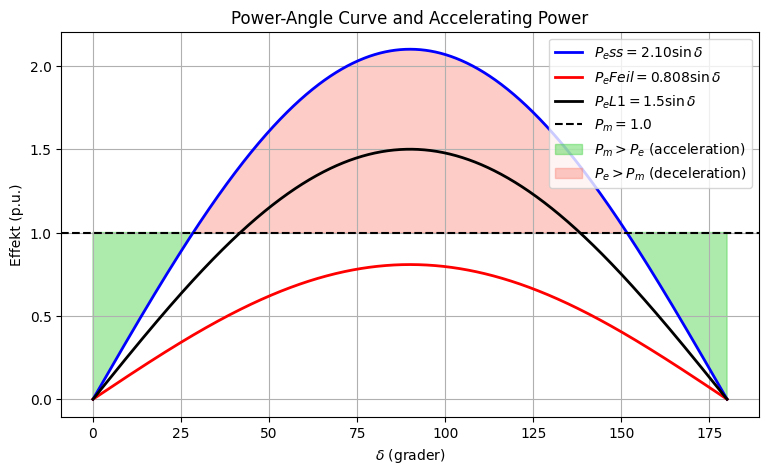

In [47]:
import numpy as np
import matplotlib.pyplot as plt

Pmax_ss = 2.10
Pmax_feil = 0.808
Pmax_L1 = 1.5
Pm = 1.0

delta_deg = np.linspace(0, 180, 1000)
delta_rad = np.radians(delta_deg)

Pe_ss = Pmax_ss * np.sin(delta_rad)
Pe_feil = Pmax_feil * np.sin(delta_rad)
Pe_L1 = Pmax_L1 * np.sin(delta_rad)

plt.figure(figsize=(9, 5))
plt.plot(delta_deg, Pe_ss, 'b', lw=2,
         label=r'$P_ess=2.10\sin\delta$')
plt.plot(delta_deg, Pe_feil, 'r', lw=2,
         label=r'$P_eFeil=0.808\sin\delta$')
plt.plot(delta_deg, Pe_L1, 'k', lw=2,
         label=r'$P_eL1=1.5\sin\delta$')
plt.axhline(Pm, color='k', ls='--',
            label=r'$P_m=1.0$')

# Akselerasjon
plt.fill_between(
    delta_deg, Pe, Pm,
    where=(Pm > Pe),
    color='limegreen',
    alpha=0.4,
    label=r'$P_m>P_e$ (acceleration)'
)

# Retardasjon
plt.fill_between(
    delta_deg, Pe, Pm,
    where=(Pe > Pm),
    color='salmon',
    alpha=0.4,
    label=r'$P_e>P_m$ (deceleration)'
)

plt.xlabel(r'$\delta$ (grader)')
plt.ylabel('Effekt (p.u.)')
plt.title('Power-Angle Curve and Accelerating Power')
plt.grid(True)
plt.legend()
plt.show()